# 整流回路

交流(+ と − に振れる信号)を、片方の向きにそろえる回路です。電源で交流を直流にする、交流の大きさを測る(交流電圧計)、音の大きさを取り出す、といった使い方をします。

ふつうのダイオードは約 0.6 V の電圧がかからないと電流が流れないので、0.6 V より小さな信号は整流できません。オペアンプと組み合わせて、この 0.6 V をなくしたものが**精密整流回路**です。この回では、半波整流、全波整流、整流した平均で交流の大きさを測る、の 3 つを見ます。

## 回路

![精密半波整流回路](04_rectifier/circuit.svg)

ダイオードをオペアンプの帰還の中に入れた回路(**スーパーダイオード**)です。出力(ダイオードの後ろ)を − 入力に戻しているので、ダイオードに電流が流れているあいだは、オペアンプがダイオードの 0.6 V のぶんだけ高い電圧を出して、出力 = 入力にします。抵抗 R の下のグランドは、Mimic でいえば Vref です。

- 入力 > Vref:ダイオードに電流が流れ、出力 = 入力。
- 入力 < Vref:オペアンプの出力が下がってダイオードが切れ、出力は R で Vref に保たれる。

**全波整流**(絶対値回路)は、この半波整流の出力と元の入力を、もう 1 つのオペアンプの加算回路で $2 \times (\text{半波}) - (\text{入力})$ のように足し合わせて作ります。

## 原理

Vref を 0 とみなすと:

| | 出力 | 正弦波(振幅 A)の出力の平均 |
|---|---|---|
| 半波整流 | 入力が + のときだけ通す($\max(x, 0)$) | $A/\pi$ = 0.318 A |
| 全波整流 | − の部分を + に折り返す($|x|$) | $2A/\pi$ = 0.637 A |

全波整流では、− の半周期も + に折り返すので、出力の山の数が 2 倍になります(周波数が 2 倍に見える)。

![整流回路の入出力特性(模式図)](04_rectifier/response.svg)

**平均値で交流を測る**:整流した出力を LPF でならすと、平均(直流)が残ります。昔からある多くの交流電圧計は、全波整流の平均に、正弦波で実効値になるような係数($\pi/(2\sqrt{2})$ = 1.111)を掛けて表示しています(**平均値形**)。正弦波なら正しく実効値が読めますが、ほかの波形では読みがずれます。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.rectifier_half(polarity)` | `mimic.setRectifierHalf(polarity)` | 半波整流。`"pos"`:$\max(x, V_\mathrm{ref})$、`"neg"`:$\min(x, V_\mathrm{ref})$(ダイオードを逆向き) |
| `lab.mimic.rectifier_full(polarity)` | `mimic.setRectifierFull(polarity)` | 全波整流。`"pos"`:$V_\mathrm{ref} + |x - V_\mathrm{ref}|$、`"neg"`:$V_\mathrm{ref} - |x - V_\mathrm{ref}|$ |

polarity を省くと `"pos"` です。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

波形(左)と、入出力特性(右:CH1 を横軸、CH2 を縦軸にした点)を並べて描く関数です。

In [2]:
def scope_xy(t, ch1, ch2, label="output", xlim=None):
    # Left: the oscilloscope; right: the input-output characteristic (CH1 across, CH2 up)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    if xlim:
        ax1.set_xlim(*xlim)
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".-", lw=0.5, ms=2, color="C2")   # thin lines show the transitions
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:半波整流

50 Hz、振幅 1 V の正弦波を半波整流します。入力が Vref(2.5 V)より高い半周期はそのまま、低い半周期は 2.5 V になるはずです。出力の平均と Vref の差は、$1/\pi$ = 0.318 V になるはずです。

mean - Vref: 0.316 V (theory 0.318 V)


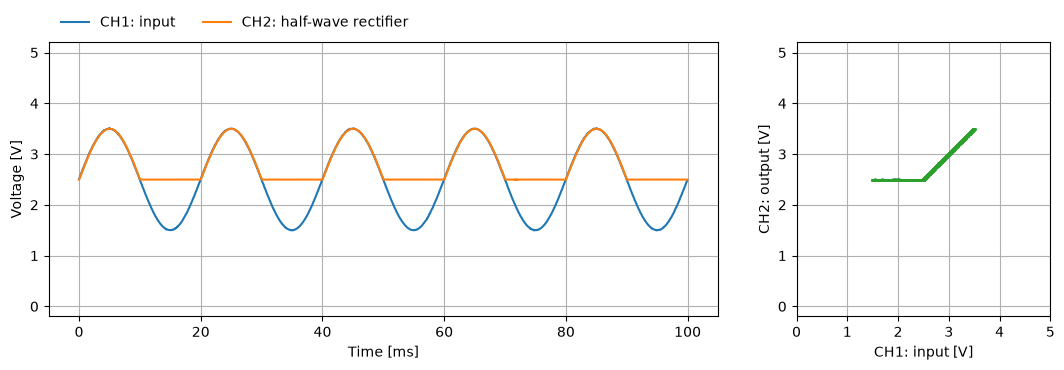

In [3]:
lab.fg.sine(50, 1.0)
lab.mimic.rectifier_half()
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s: 5 periods
print(f"mean - Vref: {ch2.mean() - 2.5:.3f} V (theory {1 / np.pi:.3f} V)")
scope_xy(t, ch1, ch2, "half-wave rectifier")

入出力特性(右)は、2.5 V で折れ曲がる線です。2.5 V のすぐ上から、入力とぴったり同じ値が出ています。ふつうのダイオードなら、入力が 0.6 V 上がるまで出力は出ません。

## 実験 2:全波整流

同じ正弦波を全波整流します。− の半周期が + に折り返されて、出力の山は 1 周期に 2 つになるはずです。平均と Vref の差は $2/\pi$ = 0.637 V です。

mean - Vref: 0.633 V (theory 0.637 V)


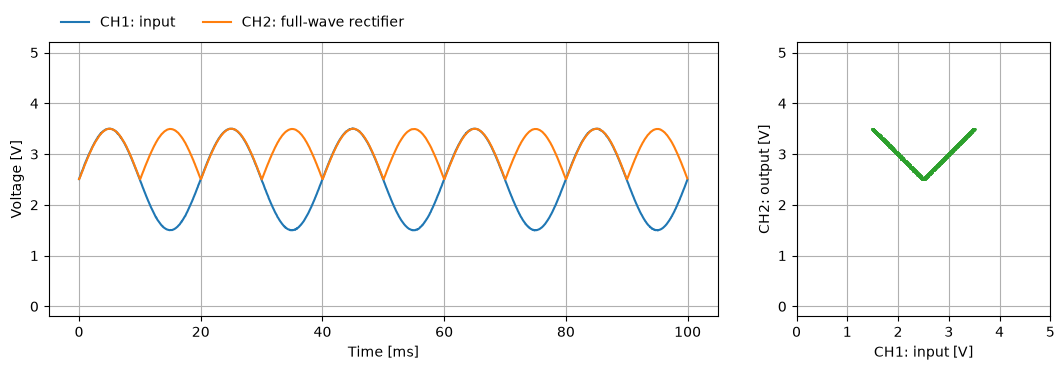

In [4]:
lab.mimic.rectifier_full()
t, ch1, ch2 = lab.scope.capture(2000)
print(f"mean - Vref: {ch2.mean() - 2.5:.3f} V (theory {2 / np.pi:.3f} V)")
scope_xy(t, ch1, ch2, "full-wave rectifier")

入出力特性は、2.5 V を谷にした V 字です。出力の山は 1 周期に 2 つ(100 Hz)になり、平均は半波整流の 2 倍です。

## 実験 3:平均値で交流の大きさを測る

振幅 1 V の正弦波、三角波、方形波を全波整流して平均をとり、平均値形の交流電圧計の読み(平均 × 1.111)と、本当の実効値(CH1 から計算)を比べます。

In [5]:
lab.mimic.rectifier_full()
waves = {"sine": lab.fg.sine, "triangle": lab.fg.triangle, "square": lab.fg.square}
print("wave       average   meter (x 1.111)   true rms   error")
for name, start in waves.items():
    start(50, 1.0)
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(2000)
    average = ch2.mean() - 2.5
    meter = average * np.pi / (2 * np.sqrt(2))
    rms = np.sqrt(np.mean((ch1 - ch1.mean()) ** 2))
    print(f"{name:9s}  {average:.3f} V   {meter:.3f} V          {rms:.3f} V    {(meter / rms - 1) * 100:+.1f} %")

wave       average   meter (x 1.111)   true rms   error
sine       0.633 V   0.703 V          0.707 V    -0.5 %
triangle   0.497 V   0.552 V          0.577 V    -4.4 %
square     0.995 V   1.106 V          0.999 V    +10.7 %


正弦波では、メーターの読みと実効値が一致します。三角波では約 4 % 小さく、方形波では約 11 % 大きく読みます(理論では、平均はそれぞれ 0.637、0.5、1.0 V、実効値は 0.707、0.577、1.0 V)。正弦波でない信号の実効値を正しく測るには、2 乗の平均の平方根を計算する**真の実効値(True RMS)**形のメーターが要ります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 極性を変える

半波整流と全波整流で、極性を `"neg"` にします。
<details><summary>ヒント</summary>

`KIND` を `"half"` と `"full"` に、`POLARITY` を `"pos"` と `"neg"` にして、4 通りを試しましょう。`"neg"` の半波整流は Vref より低い半周期だけを通し($\min(x, V_\mathrm{ref})$、ダイオードを逆向きにした回路)、全波整流は − の側に折り返します(逆さの V 字)。

</details>

mean - Vref: -0.320 V


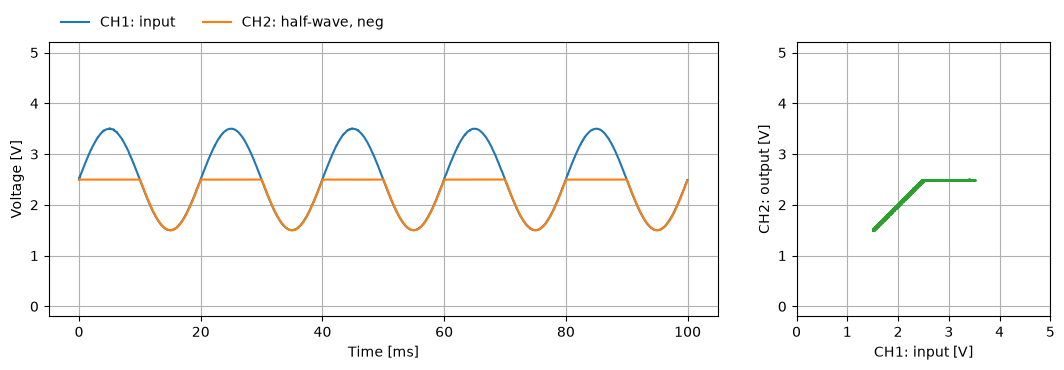

In [6]:
KIND = "half"       # "half" or "full"
POLARITY = "neg"    # "pos" or "neg"

lab.fg.sine(50, 1.0)
if KIND == "half":
    lab.mimic.rectifier_half(POLARITY)
else:
    lab.mimic.rectifier_full(POLARITY)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"mean - Vref: {ch2.mean() - 2.5:+.3f} V")
scope_xy(t, ch1, ch2, f"{KIND}-wave, {POLARITY}")

### 2. 小さな信号を整流する

精密整流回路は、ダイオードの 0.6 V よりずっと小さな信号も整流できます。振幅を小さくしていきます。
<details><summary>ヒント</summary>

`AMP` を 0.5 → 0.1 → 0.03 と変えてみましょう。0.03 V(30 mV)でも、出力は入力の + の半周期をなぞります(平均は $A/\pi$)。ふつうのダイオード 1 本の整流回路なら、0.6 V に届かないので出力は 0 のままです。ただし 30 mV では、Mimic と測定器の分解能(約 1.2 mV と 0.3 mV)や雑音が見えてきます。

</details>

mean - Vref: 157.3 mV (theory 159.2 mV)


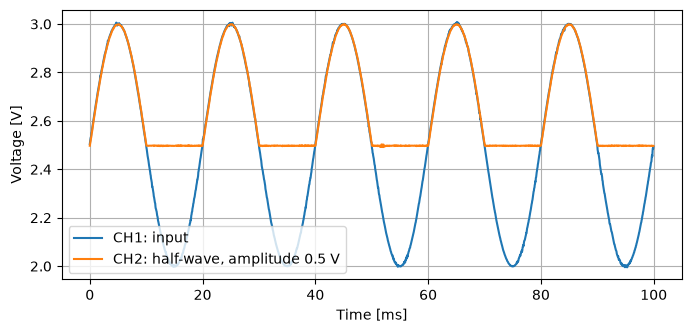

In [7]:
AMP = 0.5   # [V]

lab.fg.sine(50, AMP)
lab.mimic.rectifier_half()
t, ch1, ch2 = lab.scope.capture(2000)
print(f"mean - Vref: {(ch2.mean() - 2.5) * 1e3:.1f} mV (theory {AMP / np.pi * 1e3:.1f} mV)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: half-wave, amplitude {AMP} V")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 整流回路は交流を片方の向きにそろえる。半波整流は + だけ通し、全波整流は − を + に折り返す(絶対値)。
- オペアンプの帰還にダイオードを入れる(スーパーダイオード)と、0.6 V の順電圧がなくなり、小さな信号も正確に整流できる(精密整流回路)。
- 正弦波の全波整流の平均は振幅の $2/\pi$。平均値形の交流電圧計は正弦波を前提にしているので、ほかの波形では読みがずれる。
- Mimic では `rectifier_half(polarity)`、`rectifier_full(polarity)`。


最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [8]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()